CUSTOMER SEGMENT PREDICTION USING MULTINOMIAL REGRESSION

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

In [41]:
#Load Dataset
df = pd.read_csv("Customer Segmentation.csv")

In [42]:
df.head()

,Unnamed: 0,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,0,460394,Female,No,32,Yes,Healthcare,9.0,Low,3.0,Cat_6,D
1,1,461798,Female,No,56,Yes,Artist,0.0,Low,1.0,Cat_6,A
2,2,464976,Male,Yes,75,No,Lawyer,1.0,Low,1.0,Cat_4,D
3,3,462104,Male,Yes,39,No,Entertainment,9.0,Low,2.0,Cat_3,D
4,4,464829,Male,No,22,No,Healthcare,9.0,Low,5.0,Cat_4,D


In [43]:
#Check dataset dimension i.e rows and columns
df.shape

(10695, 12)

In [44]:
df.columns

Index(['Unnamed: 0', 'ID', 'Gender', 'Ever_Married', 'Age', 'Graduated',
       'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size',
       'Var_1', 'Segmentation'],
      dtype='object')

In [45]:
#check for missing values
df.isnull().sum()

Unnamed: 0            0
ID                    0
Gender                0
Ever_Married        190
Age                   0
Graduated           102
Profession          162
Work_Experience    1098
Spending_Score        0
Family_Size         448
Var_1               108
Segmentation          0
dtype: int64

In [46]:
#to see the uniaue values in Segmentation column
df['Segmentation'].unique()

array(['D', 'A', 'C', 'B'], dtype=object)

In [47]:
#to know the number of customers in each category
df['Segmentation'].value_counts()

Segmentation
D    3027
A    2818
C    2442
B    2408
Name: count, dtype: int64

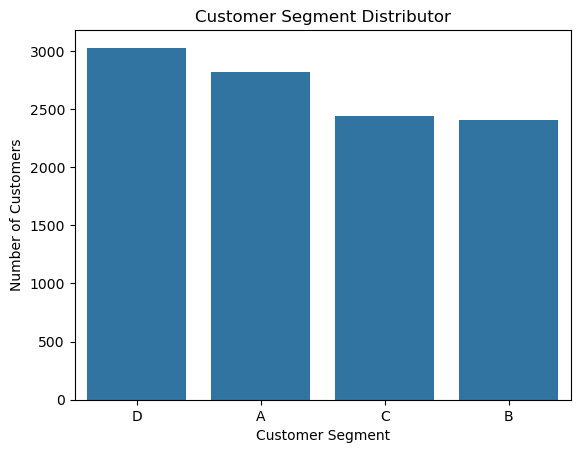

In [48]:
#visualize the target classification
sns.countplot(data=df, x="Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.title("Customer Segment Distributor")
plt.show()

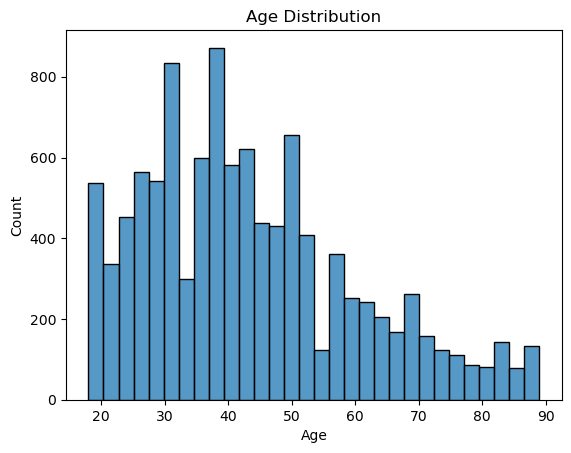

In [49]:
#visualize Age Distribution
sns.histplot(data=df, x="Age", bins=30)
plt.title("Age Distribution")
plt.show()

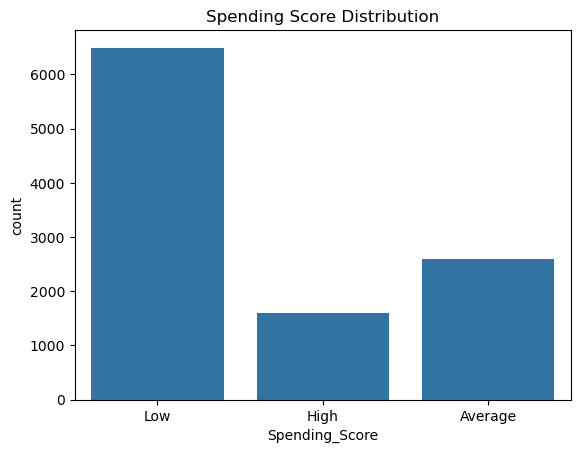

In [50]:
#visualize spending distribution
sns.countplot(data=df, x="Spending_Score")
plt.title("Spending Score Distribution")
plt.show()

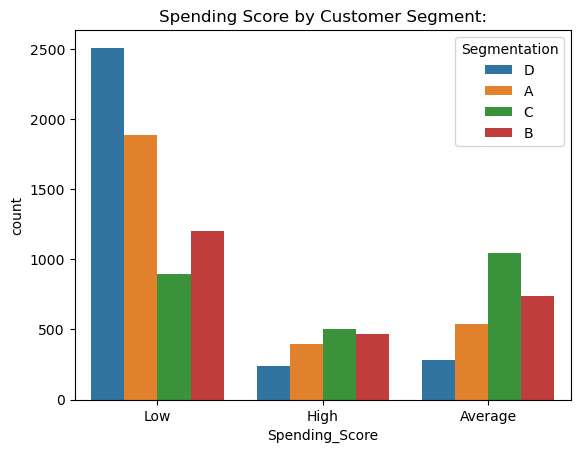

In [51]:
#visulize spending score by each customer segment
sns.countplot(data=df, x="Spending_Score", hue="Segmentation")
plt.title("Spending Score by Customer Segment:")
plt.show()

In [52]:
#select/seperate features and target
features = ["Gender",
            "Ever_Married",
            "Age",
            "Graduated",
            "Profession",
            "Work_Experience",
            "Spending_Score",
            "Family_Size"
           ]

X = df[features]
y = df['Segmentation']

HANDINLINH MISSING VALUES

In [53]:
#fill categorical missing values with the mode
categorical_columns = ["Gender", "Ever_Married", "Graduated", "Profession", "Spending_Score"]

for column in categorical_columns:
    X[column] = X[column].fillna(X[column].mode()[0])

C:\Users\Hp\AppData\Local\Temp\ipykernel_10320\2776536044.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[column] = X[column].fillna(X[column].mode()[0])


In [54]:
#fill numerical missing values with median
numerical_columns = ['Age', 'Work_Experience', 'Family_Size']

for column in numerical_columns:
    X[column] = X[column].fillna(X[column].median())

C:\Users\Hp\AppData\Local\Temp\ipykernel_10320\3205034866.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[column] = X[column].fillna(X[column].median())


In [55]:
#Encode categorical features i.e convert categorical variables to numbers

feature_encoders = {}

for column in categorical_columns:
    encoder = LabelEncoder()
    X[column] = encoder.fit_transform(X[column].astype(str))
    feature_encoders[column] = encoder

C:\Users\Hp\AppData\Local\Temp\ipykernel_10320\3650910829.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[column] = encoder.fit_transform(X[column].astype(str))
C:\Users\Hp\AppData\Local\Temp\ipykernel_10320\3650910829.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[column] = encoder.fit_transform(X[column].astype(str))
C:\Users\Hp\AppData\Local\Temp\ipykernel_10320\3650910829.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_ind

In [56]:
#encode target variables
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y.astype(str))

In [57]:
X.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size
0,0,0,32,1,5,9.0,2,3.0
1,0,0,56,1,0,0.0,2,1.0
2,1,1,75,0,7,1.0,2,1.0
3,1,1,39,0,3,9.0,2,2.0
4,1,0,22,0,5,9.0,2,5.0


In [58]:
#Data Splitting
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [59]:
#create Logistic regression model
model = LogisticRegression(max_iter=1000,random_state=42)

In [60]:
model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [61]:
#run predictions
y_pred = model.predict(X_test)

In [62]:
#print the first 10 predictions
print(y_pred[:15])

[3 3 0 0 2 3 2 2 2 2 2 0 3 0 3]


In [63]:
#print the first 15 valuse in y test
print(y_test[:15])

[3 0 0 0 1 0 3 2 2 1 2 1 3 1 3]


In [64]:
#evaluate model accuracy
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.4586255259467041


In [66]:
#predict for a new customer
new_customer = pd.DataFrame({
    "Gender": ["Female"],
    "Ever_Married": ["Yes"],
    "Age": [35],
    "Graduated":["Yes"],
    "Profession": ["Artist"],
    "Work_Experience": [5],
    "Spending_Score": ["High"],
    "Family_Size": [3]
})

In [68]:
#encode categorical values using encoders fitted on training net
for column in categorical_columns:
    new_customer[column] = new_customer[column].fillna
    new_customer[column] = feature_encoders[column].transform(new_customer[column].astype(str))

In [69]:
#make prediction
prediction = model.predict(new_customer[features])

In [70]:
print(prediction[0])

2


In [71]:
predicted_segment = target_encoder.inverse_transform(prediction)
print('Predicted Segment:', predicted_segment[0])

Predicted Segment: C
